# 19. MLOps flow for a commodity price

**Goal and requirements.** Take a forecasting model from the experiment to operation and keep it there: train, register and promote; forecast the next day's price every day, recording forecasts and observations; monitor the error against the reference; and retrain on a schedule or on an alert, with a gate that replaces the production model only when the challenger is not worse. Everything lives in an SQLite database (`ExperimentStore`). The series is the synthetic daily price of a bag of coffee, with a supply shock. `stats` and `plot` extras; no download.

In [1]:
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, save_model
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Data and protocol

`commodity_price_daily` has a slow trend, an annual harvest cycle and persistent shocks; on day 821 a supply shock raises the level by about 20 % and doubles the volatility. The model goes into production on day 600 and forecasts one step at a time (protocol B, no refit between days). The operating rules:

- **gate:** the last 60 days of each training are sealed; the challenger replaces production only if its error on those days is not larger than production's real error on the same days;
- **monitoring:** 30-day rolling MAE; alert when it exceeds 1.5 times the model's reference MAE (the sealed test one);
- **retraining:** on an alert (at most one every 60 days) or on schedule, every 120 days.

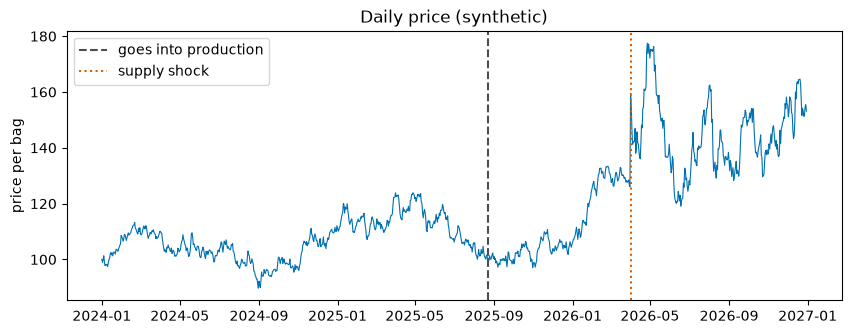

In [2]:
price = get_data("commodity_price_daily")
NAME, DEPLOY, GATE, WINDOW, THRESHOLD, SCHEDULE = "coffee_price", 600, 60, 30, 1.5, 120
SHOCK = int(len(price) * 0.75)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(price.index, price.to_numpy(), linewidth=0.8, color="#0072B2")
ax.axvline(price.index[DEPLOY], color="0.3", linestyle="--", label="goes into production")
ax.axvline(price.index[SHOCK], color="#D55E00", linestyle=":", label="supply shock")
ax.set(ylabel="price per bag", title="Daily price (synthetic)")
ax.legend()
plt.show()

## 2. Training, registration and promotion

`train` is the training pipeline: it compares the models with the last 60 days sealed, finalizes the champion, reads the sealed test once (its MAE becomes the monitoring reference), logs the experiment to the database, saves the artifact and registers it as a `candidate`. The first model goes straight to production.

In [3]:
folder = Path("artifacts/mlops")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "mlops.db")
SETTINGS = {
    "fh": 1,
    "variant": "B",
    "test_size": GATE,
    "session_id": 42,
    "budget": "smoke",
    "base_models": ["naive", "linear", "knn", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}


def train(history, label):
    exp = AutoHybridExperiment(**SETTINGS).fit(history)
    final = exp.finalize_model(exp.compare_models().best)
    mae = float(exp.evaluate_external(final).metrics["MAE"].iloc[0])
    run_id = store.log(exp, name=label, models=[final], values=True)
    path = save_model(final, folder / "models" / final.model_id[:12])
    store.register_model(final, path, name=NAME, run_id=run_id, reference_mae=mae)
    return final, mae, run_id


first, mae, _ = train(price.iloc[:DEPLOY], "initial-training")
store.promote(first.model_id, reason="first model")
store.registry(NAME)[["label", "stage", "reference_mae", "registered_utc"]]

,label,stage,reference_mae,registered_utc
0,naive,production,1.001,2026-10-14T12:20:58.724572+00:00


## 3. Daily operation

The service loads the production model from the registry (with `trusted=True` and the registered SHA-256) and updates it with the observations after its training, without refitting. Each day it forecasts the next day, records the forecast, receives the observed price, records the observation and checks the monitoring. When a retraining happens, the gate compares, on the same 60 days, the challenger's error on its sealed test with the real error production recorded.

In [4]:
def serve(t):
    """Production model from the registry, updated with the observations up to day t."""
    model = store.load(NAME, trusted=True)
    start = price.index.get_loc(model.last_observation) + 1
    return model.update_state(price.iloc[start : t + 1]).stream()


SERIES_ID = first.history.series_id
stream, events, last_retrain = serve(DEPLOY - 1), [], DEPLOY
for t in range(DEPLOY, len(price)):
    ticket = stream.predict_next()
    model_id = stream.model.model_id
    store.log_forecasts(
        model_id,
        pd.DataFrame(
            {
                "timestamp": [ticket.timestamp],
                "origin": [ticket.origin],
                "y_pred": [ticket.prediction],
            }
        ),
    )
    stream.observe(price.iloc[t])
    store.log_actuals(SERIES_ID, price.iloc[t : t + 1])
    alert = bool(store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).alert.iloc[-1])
    if not ((alert and t - last_retrain >= GATE) or t - last_retrain >= SCHEDULE):
        continue
    reason = "alert" if alert else "schedule"
    challenger, challenger_mae, run_id = train(
        price.iloc[: t + 1], f"retraining-{price.index[t].date()}"
    )
    live_mae = store.query(
        """
        SELECT AVG(ABS(a.y_true - f.y_pred)) AS mae
        FROM forecasts f JOIN actuals a USING (series_id, timestamp)
        WHERE f.model_id = ? AND f.timestamp IN (SELECT timestamp FROM predictions WHERE run_id = ?)
        """,
        (model_id, run_id),
    ).mae[0]
    promoted = challenger_mae <= live_mae
    if promoted:
        store.promote(
            challenger.model_id, reason=f"{reason}: MAE {challenger_mae:.3f} <= {live_mae:.3f}"
        )
        stream = serve(t)
    events.append(
        {
            "day": price.index[t].date(),
            "reason": reason,
            "challenger": challenger.spec.label,
            "challenger_mae": round(challenger_mae, 3),
            "production_mae": round(live_mae, 3),
            "promoted": promoted,
        }
    )
    last_retrain = t
pd.DataFrame(events)

,day,reason,challenger,challenger_mae,production_mae,promoted
0,2025-12-21,schedule,naive,0.956,0.956,True
1,2026-04-01,alert,naive,1.584,1.584,True
2,2026-06-02,alert,exponential_smoothing(season_length=7),2.859,2.862,True
3,2026-09-30,schedule,naive,2.583,2.577,False


## 4. Monitoring

The registry keeps each model's stage and the history of changes; the forecasts and observations make it possible to rebuild the real error of each model over the period it was in production.

In [5]:
store.query(
    """
    SELECT h.at, r.label, h.stage, h.reason
    FROM stage_history h JOIN registry r USING (model_id)
    WHERE h.stage <> 'candidate'
    ORDER BY h.at, h.stage
    """
)

,at,label,stage,reason
0,2026-10-14T12:20:58.731443+00:00,naive,production,first model
1,2026-10-14T12:21:14.080784+00:00,naive,archived,substituído por ea909cf8eb5f
2,2026-10-14T12:21:14.080784+00:00,naive,production,schedule: MAE 0.956 <= 0.956
3,2026-10-14T12:21:20.718010+00:00,naive,archived,substituído por dda88c3e0919
4,2026-10-14T12:21:20.718010+00:00,naive,production,alert: MAE 1.584 <= 1.584
5,2026-10-14T12:21:42.151861+00:00,naive,archived,substituído por d4b8db2509be
6,2026-10-14T12:21:42.151861+00:00,exponential_smoothing(season_length=7),production,alert: MAE 2.859 <= 2.862


In [6]:
live = store.query(
    """
    SELECT r.label, MIN(f.timestamp) AS first_day, MAX(f.timestamp) AS last_day, COUNT(*) AS days,
           ROUND(AVG(ABS(a.y_true - f.y_pred)), 3) AS live_mae,
           ROUND(r.reference_mae, 3) AS reference_mae
    FROM forecasts f
    JOIN actuals a USING (series_id, timestamp)
    JOIN registry r USING (model_id)
    GROUP BY f.model_id
    ORDER BY first_day
    """
)
live

,label,first_day,last_day,days,live_mae,reference_mae
0,naive,2025-08-23T00:00:00,2025-12-21T00:00:00,121,0.989,1.001
1,naive,2025-12-22T00:00:00,2026-04-01T00:00:00,101,1.488,0.956
2,naive,2026-04-02T00:00:00,2026-06-02T00:00:00,62,2.965,1.584
3,exponential_smoothing(season_length=7),2026-06-03T00:00:00,2026-12-30T00:00:00,211,2.515,2.859


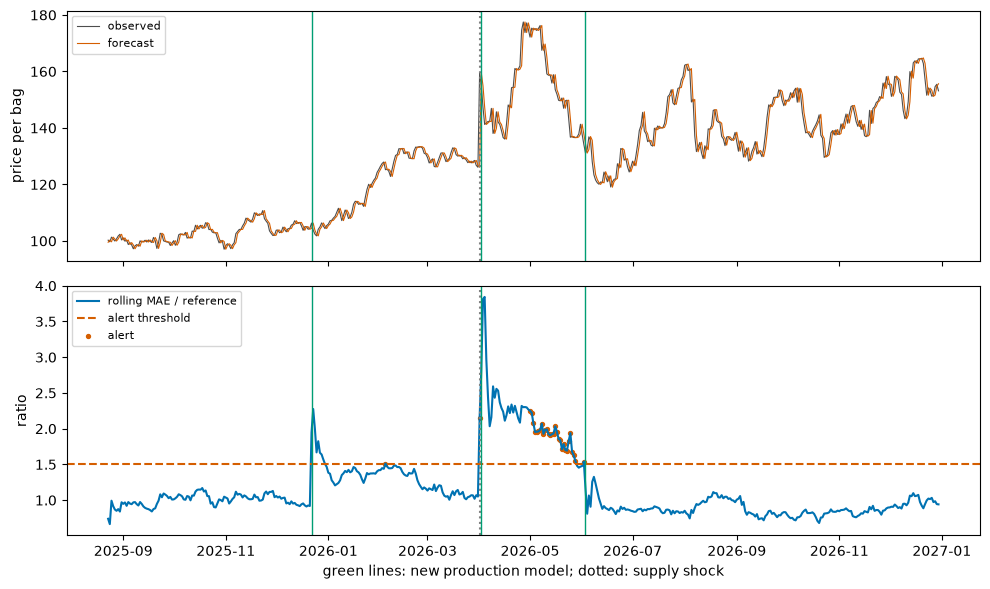

In [7]:
status = pd.concat(
    [
        store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).assign(model_id=model_id)
        for model_id in store.query("SELECT DISTINCT model_id FROM forecasts").model_id
    ]
).sort_values("timestamp")
status["timestamp"] = pd.to_datetime(status.timestamp)
promotions = store.query(
    "SELECT MIN(f.timestamp) AS first_day FROM forecasts f GROUP BY f.model_id ORDER BY first_day"
).first_day.iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
operation = price.iloc[DEPLOY:]
axes[0].plot(operation.index, operation.to_numpy(), color="0.3", linewidth=0.8, label="observed")
axes[0].plot(status.timestamp, status.y_pred, color="#D55E00", linewidth=0.8, label="forecast")
axes[0].set(ylabel="price per bag")
axes[1].plot(status.timestamp, status.ratio, color="#0072B2", label="rolling MAE / reference")
axes[1].axhline(THRESHOLD, color="#D55E00", linestyle="--", label="alert threshold")
alerts = status[status.alert]
axes[1].scatter(alerts.timestamp, alerts.ratio, s=8, color="#D55E00", label="alert")
axes[1].set(ylabel="ratio")
for ax in axes:
    ax.axvline(price.index[SHOCK], color="0.5", linestyle=":")
    for day in pd.to_datetime(promotions):
        ax.axvline(day, color="#009E73", linewidth=1)
    ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("green lines: new production model; dotted: supply shock")
fig.tight_layout()
plt.show()

## 5. Evaluating the operation

The final test of the operation is to compare the forecasts that were actually used with a simple reference, computed in the database itself: persistence (yesterday's price as today's forecast), obtained with `LAG` over the observations.

In [8]:
store.query(
    """
    WITH observed AS (
        SELECT timestamp, y_true, LAG(y_true) OVER (ORDER BY timestamp) AS persistence
        FROM actuals
    )
    SELECT CASE WHEN o.timestamp < ? THEN 'before the shock' ELSE 'after the shock' END AS period,
           COUNT(*) AS days,
           ROUND(AVG(ABS(o.y_true - f.y_pred)), 3) AS operation_mae,
           ROUND(AVG(ABS(o.y_true - o.persistence)), 3) AS persistence_mae
    FROM forecasts f JOIN observed o USING (timestamp)
    WHERE o.persistence IS NOT NULL
    GROUP BY period
    ORDER BY period
    """,
    (price.index[SHOCK].isoformat(),),
)

,period,days,operation_mae,persistence_mae
0,after the shock,274,2.729,2.727
1,before the shock,220,1.072,1.072


## 6. Reading

- **First model.** The selection chose persistence (`naive`), with a reference MAE of 1.001 on the sealed test. For a price that behaves almost like a random walk, that is expected: no model or corrector beat yesterday's price by enough to pass the acceptance rule.
- **Operation.** There were 495 days of forecasts, recorded one by one with the observations. There were four retrainings: two on schedule (2025-12-21 and 2026-09-30) and two on alerts (2026-04-01 and 2026-06-02). Three challengers passed the gate and one was refused, because its MAE on the 60 sealed days (2.583) was above production's real error on the same dates (2.577). An isolated alert on 2026-02-04 did not trigger a retraining, being less than 60 days after the previous one.
- **Supply shock.** The alert fired on the very day of the shock (2026-04-01): the price jump alone took the rolling MAE above 1.5 times the reference. The model trained that day still had a reference from the old regime (1.584), and the alerts came back from 05-01 to 06-02, while retraining waited for the at-most-one-every-60-days rule. Only the 06-02 retraining, with 60 days of the new regime in its test, brought a consistent reference (2.859): the ETS that came in had no alert until the end.
- **Real error × reference.** The first model stayed close to its reference (0.989 against 1.001). The next two went through the shock with references from the old regime and stayed well above them (1.488 against 0.956 and 2.965 against 1.584). The ETS stayed below its own (2.515 against 2.859). Monitoring measures exactly that distance.
- **Against persistence.** The forecasts used in operation had the same MAE as persistence before the shock (1.072) and practically the same after it (2.729 against 2.727). The value of the flow, on this series, is not in forecasting better than yesterday's price: it is in noticing the regime change, refreshing the reference and keeping every change recorded and auditable.
- **Trail.** The database keeps each training's experiments, the model registry with the artifacts' SHA-256, the stage history with its reasons and every forecast and observation: any question about the operation can be answered later, with SQL.